# Zillow Showcase: how is it tracking over the last 2 months?

**Data:** 72degree Zillow listings feed, which is a snapshot of active for-sale and pending listings.
- `BOTS.Z.LISTINGS_AGG`: snapshot level, flag `is_showcase_listing`.
- `BOTS.Z.LISTING_DETAILS`: one row per `listing_id`; a listing counts as Showcase if any of its snapshots was flagged.
- `BOTS.Z.LISTINGS_V3` / `LISTINGS_ALL`: the raw feed, always queried with a date filter.

**Benchmark:** Visible Alpha Residential revenue lines (`data/va_benchmarks.csv`), plus management's Showcase disclosures.

**Feed caveats:**
- The v2 feed stops at the **2026-07-02** snapshot and v3 starts on **2026-08-02**, so **there is no July 2026 snapshot**.
- Snapshots were about twice a month and have been weekly since 2026-08-25.
- From 2026-08-25, v3 also carries `FORECLOSED` / `PRE_FORECLOSURE` rows (about 50k). These are never Showcase, so they are excluded from the share denominator.

In [1]:
import sys, warnings
sys.path.insert(0, ".")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, matplotlib.dates as mdates
from common import q, va, backtest_stats, OUT
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)

# reference categorical palette (dataviz skill, light mode), fixed order
C = {"s1": "#2a78d6", "s2": "#eb6834", "s3": "#1baf7a", "s4": "#eda100", "ink": "#0b0b0b", "ink2": "#52514e", "grid": "#e4e3df"}
plt.rcParams.update({"figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": C["grid"],
    "axes.grid": True, "grid.color": C["grid"], "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False,
    "lines.linewidth": 2, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold", "text.color": C["ink"],
    "axes.labelcolor": C["ink2"], "xtick.color": C["ink2"], "ytick.color": C["ink2"], "legend.frameon": False})
def save(fig, name):
    fig.tight_layout(); fig.savefig(OUT / f"showcase_{name}.png", dpi=150); plt.show()
V2V3_GAP = (pd.Timestamp("2026-07-02"), pd.Timestamp("2026-08-02"))

## 1. Management disclosures (benchmark context)

From the Q2-26 call (2026-08-05) and the Goldman Sachs Communacopia fireside chat (2026-09-10), via SRS documents (Quartr):
- **Showcase is on ~5% of new listings, up from ~2.5% a year ago.** Agents who use Showcase on most of their listings win 35% more listings.
- In the top 10 markets, Showcase is on more than 10% of new for-sale listings. Rich media is on 11% of new for-sale listings nationally.
- Showcase revenue sits in **Residential** (For Sale). It is named as a growth driver alongside New Construction and software. **No Showcase revenue figure, run-rate or pricing is disclosed.**
- **Q3-26 guidance:** Residential flat YoY, with 600–700 bps of revenue moving from Residential to Mortgages because of Zillow Preferred. For Sale revenue +5–7%.
- **Preview:** "quite small". Private listings are 1–2% of inventory (5–10k listings).
- Management used no saturation language ("we're nowhere near done").

The Residential shift into Mortgages makes reported Residential a noisy target for any Showcase signal in Q3-26.

## 2. Active Showcase listings and share, by snapshot

In [2]:
snap = q("""select date, sum(listings) n_all, sum(iff(is_showcase_listing, listings, 0)) sc
            from bots.z.listings_agg where date >= '2023-08-13' group by 1 order by 1""")
snap["date"] = pd.to_datetime(snap["date"])
# for-sale + pending denominator (exclude foreclosure statuses that v3 added from 2026-08-25)
v3 = q("""select rundate::date date, count_if(property_status in ('FOR_SALE','PENDING')) n_fsp,
             count_if(property_status in ('FORECLOSED','PRE_FORECLOSURE')) n_fc
          from bots.z.listings_v3 where rundate >= '2026-08-01' group by 1""")
v3["date"] = pd.to_datetime(v3["date"])
snap = snap.merge(v3, on="date", how="left")
snap["n_clean"] = snap["n_fsp"].fillna(snap["n_all"])
snap["share"] = snap["sc"] / snap["n_clean"]
# YoY vs the nearest snapshot ~1 year earlier (within 10 days)
prev = snap[["date", "sc", "share"]].rename(columns={"sc": "sc_ly", "share": "share_ly"})
prev["date"] = prev["date"] + pd.DateOffset(years=1)
snap = pd.merge_asof(snap.sort_values("date"), prev.sort_values("date"), on="date", direction="nearest", tolerance=pd.Timedelta("10D"))
snap["sc_yoy"] = snap["sc"] / snap["sc_ly"] - 1
recent = snap[snap["date"] >= "2026-05-01"].copy()
recent[["date", "sc", "n_clean", "n_fc", "share", "sc_ly", "sc_yoy", "share_ly"]].style.format(
    {"sc": "{:,.0f}", "n_clean": "{:,.0f}", "n_fc": "{:,.0f}", "share": "{:.2%}", "sc_ly": "{:,.0f}", "sc_yoy": "{:+.0%}", "share_ly": "{:.2%}"}, na_rep="")

Initiating login request with your identity provider. A browser window should have opened for you to complete the login. If you can't see it, check existing browser windows, or your OS settings. Press CTRL+C to abort and try again...


,date,sc,n_clean,n_fc,share,sc_ly,sc_yoy,share_ly
69,2026-05-02 00:00:00,"50,990","2,435,323",,2.09%,"25,113",+103%,0.98%
70,2026-05-16 00:00:00,"53,812","2,494,819",,2.16%,"24,468",+120%,1.02%
71,2026-06-02 00:00:00,"57,528","2,521,297",,2.28%,"25,227",+128%,1.04%
72,2026-07-02 00:00:00,"61,755","2,575,329",,2.40%,"28,077",+120%,1.11%
73,2026-08-02 00:00:00,"60,611","2,473,276",0,2.45%,"28,426",+113%,1.17%
74,2026-08-16 00:00:00,"59,451","2,435,511",0,2.44%,"29,021",+105%,1.19%
75,2026-08-25 00:00:00,"61,246","2,470,803","49,805",2.48%,"30,113",+103%,1.24%
76,2026-09-01 00:00:00,"60,536","2,434,086","49,636",2.49%,"30,113",+101%,1.24%
77,2026-09-08 00:00:00,"61,406","2,448,643","49,521",2.51%,"30,113",+104%,1.24%
78,2026-09-15 00:00:00,"62,492","2,468,494","49,917",2.53%,"31,640",+98%,1.30%


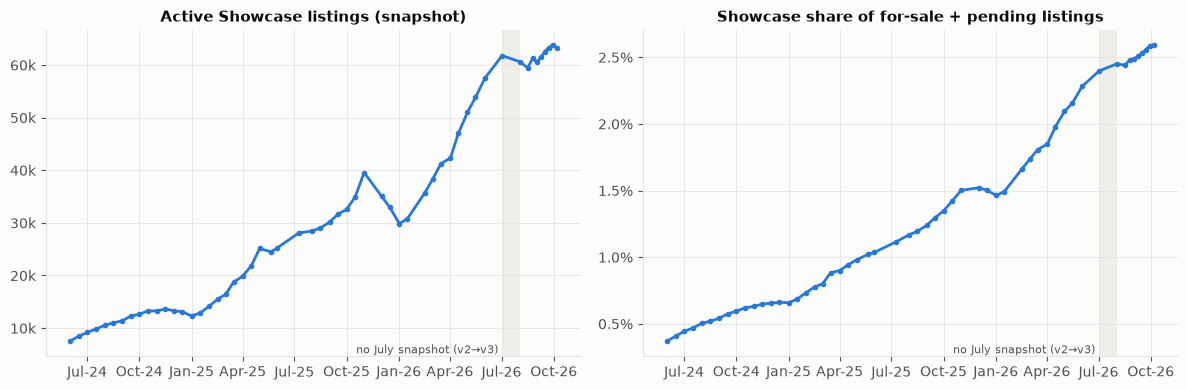

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
s = snap[snap["date"] >= "2024-06-01"]
for ax, col, title, fmt in [(axes[0], "sc", "Active Showcase listings (snapshot)", lambda v, _: f"{v/1e3:.0f}k"),
                            (axes[1], "share", "Showcase share of for-sale + pending listings", lambda v, _: f"{v:.1%}")]:
    ax.plot(s["date"], s[col], color=C["s1"], marker="o", markersize=3)
    ax.axvspan(*V2V3_GAP, color=C["grid"], alpha=0.6, lw=0)
    ax.text(V2V3_GAP[0], ax.get_ylim()[0], "no July snapshot (v2→v3) ", va="bottom", ha="right", fontsize=8, color=C["ink2"])
    ax.set_title(title); ax.yaxis.set_major_formatter(plt.FuncFormatter(fmt))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b-%y"))
save(fig, "active_share")

## 2b. Reconciling to management's "% of new listings"

Management's series is the share of **new listings** with Showcase, a flow measure. As stated on each call:

| Quarter | Q4-24 | Q1-25 | Q2-25 | Q3-25 | Q4-25 | Q1-26 | Q2-26 |
|---|---|---|---|---|---|---|---|
| Management | 1.7% | 2.0% | 2.5% | 3.2% | 3.7% | 4.3% | ~5% |

The 2.59% in section 2 is the share of the **active stock**, a different measure. Showcase homes sell faster and leave the stock
sooner, and the stock includes about 475k vacant lots, which are almost never Showcase.

**Our comparable measure:** listings starting in the quarter (`LISTING_DETAILS`, first seen as FOR_SALE) that carry Showcase on
any snapshot. Two denominators:
- **Agent-listed homes:** single family, condo or townhouse with a broker name. This is the closest to Zillow's likely definition.
- **All non-lot listings.**

Q3-26 is provisional: its listings haven't had time to switch on Showcase, and there is no July snapshot.

,management,ours: agent-listed homes,ours: all non-lot,active stock share (section 2),mgmt ÷ ours (agent homes)
2024Q4,1.70%,1.47%,1.22%,0.63%,1.16x
2025Q1,2.00%,1.94%,1.61%,0.76%,1.03x
2025Q2,2.50%,2.19%,1.87%,0.98%,1.14x
2025Q3,3.20%,2.66%,2.27%,1.20%,1.20x
2025Q4,3.70%,3.20%,2.68%,1.46%,1.16x
2026Q1,4.30%,3.92%,3.35%,1.63%,1.10x
2026Q2,5.00%,4.38%,3.85%,2.07%,1.14x
2026Q3,–,4.14%,3.58%,2.49%,–


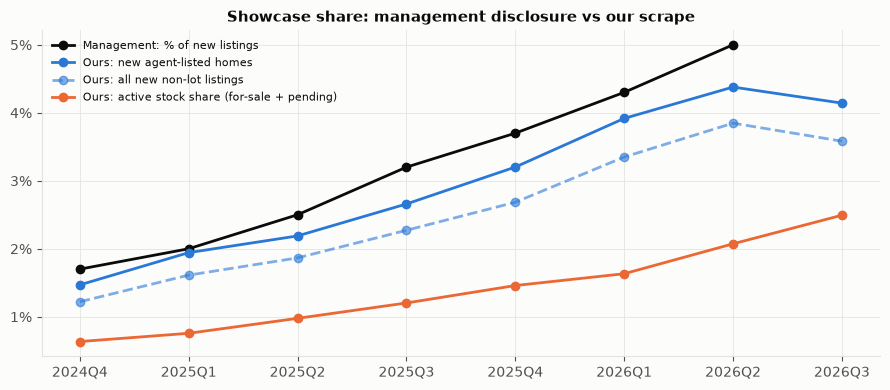

In [4]:
mgmt = pd.Series({"2024Q4": .017, "2025Q1": .020, "2025Q2": .025, "2025Q3": .032, "2025Q4": .037, "2026Q1": .043, "2026Q2": .050})
mgmt.index = pd.PeriodIndex(mgmt.index, freq="Q")
nlq = q("""
select date_trunc('quarter', d.date) qtr,
  count_if(a.pt <> 'LOT') starts_nonlot, count_if(a.pt <> 'LOT' and d.is_showcase_listing) sc_nonlot,
  count_if(a.home) starts_home, count_if(a.home and d.is_showcase_listing) sc_home
from bots.z.listing_details d
join (select property_id, rundate::date rd, property_type pt,
        property_type in ('SINGLE_FAMILY','CONDO','TOWNHOUSE') and nullif(trim(broker_name),'') is not null home
      from bots.z.listings_all where rundate >= '2024-09-15' and property_status = 'FOR_SALE'
      qualify row_number() over (partition by property_id, rundate::date order by insert_update_time desc) = 1) a
  on a.property_id = d.property_id and a.rd = d.date
where d.date >= '2024-10-01' group by 1 order by 1""")
nlq["quarter"] = pd.to_datetime(nlq["qtr"]).dt.to_period("Q")
nlq = nlq.set_index("quarter")
rec = pd.DataFrame({"management": mgmt,
                    "ours: agent-listed homes": nlq["sc_home"] / nlq["starts_home"],
                    "ours: all non-lot": nlq["sc_nonlot"] / nlq["starts_nonlot"],
                    "active stock share (section 2)": snap.assign(qt=snap["date"].dt.to_period("Q")).groupby("qt")["share"].mean()
                    }).loc["2024Q4":"2026Q3"]
rec["mgmt ÷ ours (agent homes)"] = rec["management"] / rec["ours: agent-listed homes"]
display(rec.style.format({c: "{:.2%}" for c in rec.columns[:4]} | {"mgmt ÷ ours (agent homes)": "{:.2f}x"}, na_rep="–"))

fig, ax = plt.subplots(figsize=(9, 4))
xi = rec.index.astype(str)
ax.plot(xi, rec["management"], color=C["ink"], marker="o", label="Management: % of new listings")
ax.plot(xi, rec["ours: agent-listed homes"], color=C["s1"], marker="o", label="Ours: new agent-listed homes")
ax.plot(xi, rec["ours: all non-lot"], color=C["s1"], marker="o", ls="--", alpha=0.6, label="Ours: all new non-lot listings")
ax.plot(xi, rec["active stock share (section 2)"], color=C["s2"], marker="o", label="Ours: active stock share (for-sale + pending)")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("Showcase share: management disclosure vs our scrape"); ax.legend(fontsize=8, loc="upper left")
save(fig, "vs_management")

## 2c. Monthly and quarterly view, and a Q3-26 estimate of management's metric

**How management defines it.** No calculation is ever given; the shareholder letters footnote only product URLs. The wording,
however, is consistent:
- Q1-25: "as of the end of March … about 2% of all new **for-sale** listings, up from 1.7% at the **end of last year**".
- Q3-25: "as of the end of Q3 … 3.2% of all new listings in the **U.S.**".
- The Q4-25 deck plots "% of New Listings" at **year-end** points: 0.5% / 1.7% / 3.7%.

Agent-listed versus all listings, and whether listings that add Showcase later are counted, are not stated.

**Our population.** New agent-listed homes: single family, condo or townhouse with a broker name, FOR_SALE when first seen,
dated to their **listing month** (first-seen date minus Zillow's `listing_age`).

**Two versions of the numerator.** In both, Showcase is read straight from our weekly snapshots.
- **A. Point-in-time:** Showcase showing on a snapshot by the end of the listing's own month (monthly view) or quarter
  (quarterly view). For listings we first see after that date, their status at first sighting is used.
- **B. Reporting-lag basis:** Showcase showing on a snapshot by **quarter-end + 35 days**. This mimics management counting
  about five weeks after quarter-end; the Q2 call was on Aug 5. Every month in a quarter shares the same calendar cutoff, so the
  quarterly figure is the listing-weighted average of its months.

**Q3-26 under B is projected.** Its cutoff (Nov 4) is after our latest snapshot. Each Q3 month's share today is scaled by how
much the cohort one month older grew over the last 28 days. That cohort is at the same age and under the same weekly cadence.

**Estimate.** Sequential, as recommended: management's Q2 figure × (our Q3 ÷ our Q2), using the quarterly average.
- The band is ±1.28 × the RMSE of the same method backtested on Q1-25 to Q2-26 (roughly 80%). The B band also includes the
  projection uncertainty.
- Management's figures are rounded ("about 5%"), which adds noise of its own.

In [5]:
VSQL = """
with snaps as (select property_id, rundate::date rd, property_type pt, property_status st, broker_name bn, listing_age age,
                      nvl(is_showcase_listing,false) sc
               from bots.z.listings_all where rundate >= '2024-09-01'
               qualify row_number() over (partition by property_id, rundate::date order by insert_update_time desc) = 1),
f as (select d.listing_id, d.property_id, d.date fs, iff(a.age between 0 and 45, dateadd('day', -a.age, d.date), d.date) listed
      from bots.z.listing_details d join snaps a on a.property_id = d.property_id and a.rd = d.date
      where d.date >= '2024-10-01' and a.st = 'FOR_SALE'
        and a.pt in ('SINGLE_FAMILY','CONDO','TOWNHOUSE') and nullif(trim(a.bn),'') is not null),
g as (select f.*, last_day(listed) me, last_day(listed, 'quarter') qe from f where listed >= '2024-10-01'),
x as (select g.listing_id, g.listed,
        max(iff(b.sc and (b.rd <= g.me or b.rd = g.fs), 1, 0)) pit_m,
        max(iff(b.sc and (b.rd <= g.qe or b.rd = g.fs), 1, 0)) pit_q,
        max(iff(b.sc and (b.rd <= dateadd('day', 35, g.qe) or b.rd = g.fs), 1, 0)) lag35
      from g join snaps b on b.property_id = g.property_id and b.rd between g.fs and greatest(dateadd('day', 35, g.qe), g.fs)
      group by 1, 2)
select date_trunc('month', listed) mo, count(*) n, sum(pit_m) pit_m, sum(pit_q) pit_q, sum(lag35) lag35
from x group by 1 order by 1"""
vm = q(VSQL)
vm["mo"] = pd.to_datetime(vm["mo"]).dt.to_period("M")
vm = vm.set_index("mo").astype(float)
DATA_END = pd.Timestamp(q("select max(rundate)::date d from bots.z.listings_v3")["d"].iloc[0])
S1 = pd.Timestamp(q(f"select max(rundate)::date d from bots.z.listings_v3 where rundate::date <= '{(DATA_END - pd.Timedelta(days=28)).date()}'")["d"].iloc[0])
vm = vm.loc[:pd.Period(DATA_END, "M") - 1]           # drop the partial current month

# B projection: months whose quarter-end + 35d is after DATA_END
proj = [p for p in vm.index if p.asfreq("Q").end_time.normalize() + pd.Timedelta(days=35) > DATA_END]
mat = q(f"""
with snaps as (select property_id, rundate::date rd, property_type pt, property_status st, broker_name bn, listing_age age,
                      nvl(is_showcase_listing,false) sc
               from bots.z.listings_all where rundate >= '{(proj[0] - 2).start_time.date()}'
               qualify row_number() over (partition by property_id, rundate::date order by insert_update_time desc) = 1),
f as (select d.property_id, d.date fs, date_trunc('month', iff(a.age between 0 and 45, dateadd('day', -a.age, d.date), d.date)) mo
      from bots.z.listing_details d join snaps a on a.property_id = d.property_id and a.rd = d.date
      where a.st = 'FOR_SALE' and a.pt in ('SINGLE_FAMILY','CONDO','TOWNHOUSE') and nullif(trim(a.bn),'') is not null
        and d.date <= '{S1.date()}'),
x as (select f.property_id, f.mo, max(iff(b.sc and b.rd <= '{S1.date()}', 1, 0)) e, max(iff(b.sc and b.rd <= '{DATA_END.date()}', 1, 0)) l
      from f join snaps b on b.property_id = f.property_id and b.rd >= f.fs group by 1, 2)
select mo, sum(l) / sum(e) ratio from x
where mo between '{(proj[0] - 1).start_time.date()}' and '{(proj[-1] - 1).start_time.date()}' group by 1""")
mat["mo"] = pd.to_datetime(mat["mo"]).dt.to_period("M")
growth = mat.set_index("mo")["ratio"].astype(float)
vm["lag35_obs"] = vm["lag35"]
for p in proj:
    vm.loc[p, "lag35"] = vm.loc[p, "lag35_obs"] * growth[p - 1]
print(f"Data to {DATA_END.date()}; B projected for {[str(p) for p in proj]} using older-cohort growth "
      f"{S1.date()}→{DATA_END.date()}: " + ", ".join(f"{p - 1}: ×{growth[p - 1]:.3f}" for p in proj))

for c in ["pit_m", "pit_q", "lag35", "lag35_obs"]:
    vm[c + "_sh"] = vm[c] / vm["n"]
vq = vm.groupby(vm.index.asfreq("Q"))[["n", "pit_q", "lag35", "lag35_obs"]].sum()
vq["A"] = vq["pit_q"] / vq["n"]; vq["B"] = vq["lag35"] / vq["n"]; vq["B_obs"] = vq["lag35_obs"] / vq["n"]
mgq = pd.Series(mgmt.to_numpy(), index=mgmt.index)          # from 2b: Q4-24 … Q2-26
vq["mgmt"] = mgq
display(vm[["n", "pit_m_sh", "lag35_obs_sh", "lag35_sh"]].rename(columns={"pit_m_sh": "A point-in-time (month)",
        "lag35_obs_sh": "B observed", "lag35_sh": "B (projected where needed)"})
        .style.format({"n": "{:,.0f}"} | {c: "{:.2%}" for c in ["A point-in-time (month)", "B observed", "B (projected where needed)"]}))

# Sequential backtest + Q3-26 estimate for each version
LASTQ = vq.index[-1]
est = {}
for v in ["A", "B"]:
    s = vq["mgmt"].shift(1) * vq[v] / vq[v].shift(1)
    err = (s / vq["mgmt"] - 1).loc["2025Q1":]
    rmse = float(np.sqrt((err.dropna() ** 2).mean()))
    proj_sd = 0.5 * (vq.loc[LASTQ, "B"] / vq.loc[LASTQ, "B_obs"] - 1) if v == "B" else 0.0   # half the projection uplift as 1 s.d.
    sd = float(np.hypot(rmse, proj_sd))
    e = float(vq.loc[LASTQ - 1, "mgmt"] * vq.loc[LASTQ, v] / vq.loc[LASTQ - 1, v])
    est[v] = {"ours Q2-26": vq.loc[LASTQ - 1, v], "ours Q3-26": vq.loc[LASTQ, v], "Q/Q": vq.loc[LASTQ, v] / vq.loc[LASTQ - 1, v] - 1,
              "Q3-26 est": e, "lo (80%)": e * (1 - 1.28 * sd), "hi (80%)": e * (1 + 1.28 * sd),
              "backtest MAPE": err.abs().mean(), "backtest RMSE": rmse, "backtest bias": err.mean(), "n": err.notna().sum()}
    vq[f"seq_{v}"] = s
est = pd.DataFrame(est).T
display(vq[["A", "B", "mgmt", "seq_A", "seq_B"]].style.format("{:.2%}", na_rep="–"))
est.style.format({c: "{:.2%}" for c in ["ours Q2-26", "ours Q3-26", "Q3-26 est", "lo (80%)", "hi (80%)"]}
                 | {"Q/Q": "{:+.1%}", "backtest MAPE": "{:.1%}", "backtest RMSE": "{:.1%}", "backtest bias": "{:+.1%}", "n": "{:.0f}"})

Data to 2026-10-06; B projected for ['2026-07', '2026-08', '2026-09'] using older-cohort growth 2026-09-08→2026-10-06: 2026-06: ×1.035, 2026-07: ×1.043, 2026-08: ×1.080


,n,A point-in-time (month),B observed,B (projected where needed)
mo,,,,
2024-10,"255,380",0.85%,1.18%,1.18%
2024-11,"200,108",0.86%,1.19%,1.19%
2024-12,"170,114",0.94%,1.16%,1.16%
2025-01,"225,467",1.13%,1.58%,1.58%
2025-02,"238,025",1.21%,1.68%,1.68%
2025-03,"342,135",1.23%,1.60%,1.60%
2025-04,"454,315",1.33%,1.90%,1.90%
2025-05,"230,547",1.30%,1.81%,1.81%
2025-06,"224,269",1.60%,1.84%,1.84%


,A,B,mgmt,seq_A,seq_B
mo,,,,,
2024Q4,1.04%,1.18%,1.70%,–,–
2025Q1,1.38%,1.62%,2.00%,2.26%,2.34%
2025Q2,1.60%,1.86%,2.50%,2.31%,2.30%
2025Q3,2.03%,2.37%,3.20%,3.18%,3.18%
2025Q4,2.49%,2.70%,3.70%,3.93%,3.64%
2026Q1,3.07%,3.57%,4.30%,4.56%,4.88%
2026Q2,3.65%,4.15%,5.00%,5.11%,5.00%
2026Q3,3.97%,4.29%,–,5.44%,5.18%


,ours Q2-26,ours Q3-26,Q/Q,Q3-26 est,lo (80%),hi (80%),backtest MAPE,backtest RMSE,backtest bias,n
A,3.65%,3.97%,+8.7%,5.44%,4.94%,5.93%,5.9%,7.1%,+3.2%,6
B,4.15%,4.29%,+3.5%,5.18%,4.53%,5.82%,6.7%,9.4%,+3.4%,6


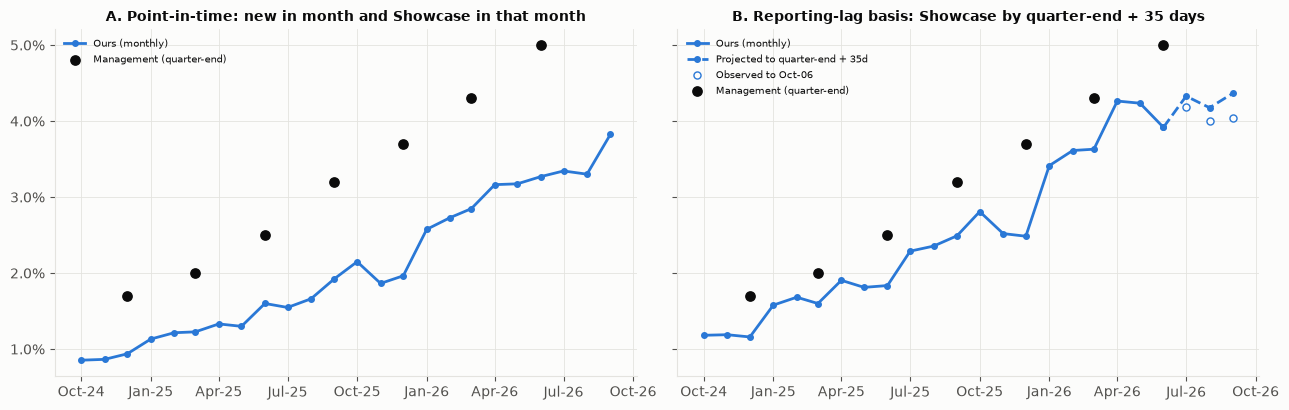

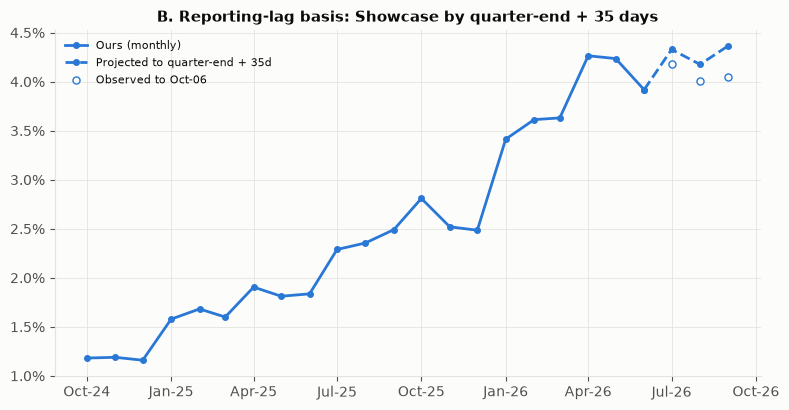

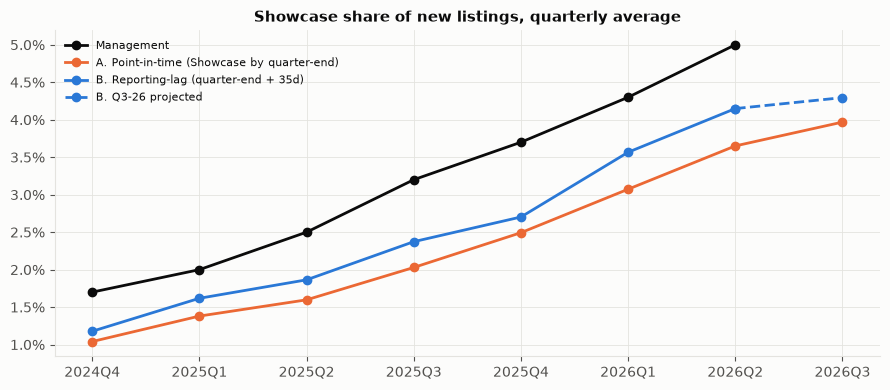

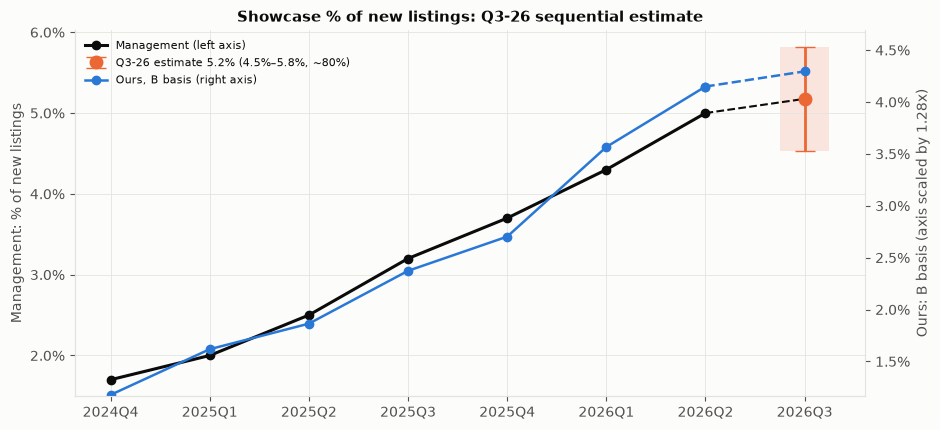

In [6]:
# Monthly: A and B side by side, management at quarter-end months
mg_m = pd.Series(mgq.to_numpy(), index=mgq.index.asfreq("M", how="end"))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
xm = vm.index.to_timestamp()
pm = vm.index.isin(proj)
for ax, col, title in [(axes[0], "pit_m_sh", "A. Point-in-time: new in month and Showcase in that month"),
                       (axes[1], "lag35_sh", "B. Reporting-lag basis: Showcase by quarter-end + 35 days")]:
    ax.plot(xm[~pm | (col == "pit_m_sh")], vm.loc[~pm | (col == "pit_m_sh"), col], color=C["s1"], marker="o", ms=4, label="Ours (monthly)")
    if col == "lag35_sh":
        i0 = int(np.argmax(pm)) - 1
        ax.plot(xm[i0:], vm[col].iloc[i0:], color=C["s1"], ls="--", marker="o", ms=4, label="Projected to quarter-end + 35d")
        ax.scatter(xm[pm], vm.loc[pm, "lag35_obs_sh"], facecolor="#fcfcfb", edgecolor=C["s1"], s=26, zorder=3, label=f"Observed to {DATA_END:%b-%d}")
    ax.scatter(mg_m.index.to_timestamp(), mg_m, color=C["ink"], s=45, zorder=4, label="Management (quarter-end)")
    ax.set_title(title, fontsize=10); ax.legend(fontsize=7.5, loc="upper left")
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.1%}")); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b-%y"))
save(fig, "newlisting_monthly_versions")

# B monthly on its own, without management points
fig, ax = plt.subplots(figsize=(8, 4.2))
i0 = int(np.argmax(pm)) - 1
ax.plot(xm[:i0 + 1], vm["lag35_sh"].iloc[:i0 + 1], color=C["s1"], marker="o", ms=4, label="Ours (monthly)")
ax.plot(xm[i0:], vm["lag35_sh"].iloc[i0:], color=C["s1"], ls="--", marker="o", ms=4, label="Projected to quarter-end + 35d")
ax.scatter(xm[pm], vm.loc[pm, "lag35_obs_sh"], facecolor="#fcfcfb", edgecolor=C["s1"], s=26, zorder=3, label=f"Observed to {DATA_END:%b-%d}")
ax.set_title("B. Reporting-lag basis: Showcase by quarter-end + 35 days"); ax.legend(fontsize=8, loc="upper left")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.1%}")); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b-%y"))
save(fig, "newlisting_monthly_B")

# Quarterly: A, B and management
fig, ax = plt.subplots(figsize=(9, 4))
xq = vq.index.astype(str)
ax.plot(xq, vq["mgmt"], color=C["ink"], marker="o", label="Management")
ax.plot(xq, vq["A"], color=C["s2"], marker="o", label="A. Point-in-time (Showcase by quarter-end)")
ax.plot(xq[:-1], vq["B"].iloc[:-1], color=C["s1"], marker="o", label="B. Reporting-lag (quarter-end + 35d)")
ax.plot(xq[-2:], vq["B"].iloc[-2:], color=C["s1"], marker="o", ls="--", label="B. Q3-26 projected")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.1%}"))
ax.set_title("Showcase share of new listings, quarterly average"); ax.legend(fontsize=8, loc="upper left")
save(fig, "newlisting_quarterly_versions")

# Estimate chart: management (left axis) with sequential Q3-26 estimate + band; our B signal (right axis)
b = est.loc["B"]
fig, ax = plt.subplots(figsize=(9.5, 4.4))
ax.plot(xq[:-1], vq["mgmt"].iloc[:-1], color=C["ink"], marker="o", lw=2.2, label="Management (left axis)")
ax.plot(xq[-2:], [vq["mgmt"].iloc[-2], b["Q3-26 est"]], color=C["ink"], ls="--", lw=1.5)
ax.errorbar([xq[-1]], [b["Q3-26 est"]], yerr=[[b["Q3-26 est"] - b["lo (80%)"]], [b["hi (80%)"] - b["Q3-26 est"]]],
            fmt="o", color=C["s2"], ms=9, capsize=7, lw=2, label=f"Q3-26 estimate {b['Q3-26 est']:.1%} ({b['lo (80%)']:.1%}–{b['hi (80%)']:.1%}, ~80%)")
ax.fill_between([len(xq) - 1.25, len(xq) - 0.75], b["lo (80%)"], b["hi (80%)"], color=C["s2"], alpha=0.15, lw=0)
ax.set_ylabel("Management: % of new listings")
ax2 = ax.twinx()
ax2.plot(xq[:-1], vq["B"].iloc[:-1], color=C["s1"], marker="o", lw=1.8, label="Ours, B basis (right axis)")
ax2.plot(xq[-2:], vq["B"].iloc[-2:], color=C["s1"], marker="o", lw=1.8, ls="--")
r_ = (vq["mgmt"] / vq["B"]).loc["2025Q1":"2026Q2"].mean()       # scale right axis so the two series overlay on average
lo_, hi_ = ax.get_ylim(); ax2.set_ylim(lo_ / r_, hi_ / r_)
ax2.grid(False); ax2.spines["right"].set_visible(True)
ax2.set_ylabel(f"Ours: B basis (axis scaled by {r_:.2f}x)")
for a in (ax, ax2):
    a.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.1%}"))
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, fontsize=8, loc="upper left")
ax.set_title("Showcase % of new listings: Q3-26 sequential estimate")
save(fig, "newlisting_estimate")

## 3. Benchmark: does the Showcase signal track reported revenue?

Showcase has no reported KPI. The nearest reported lines are VA **Other Residential revenue**, which includes Showcase, New Construction, software and StreetEasy, and **Residential** (= Premier Agent + Other Residential).

- **Quarterly signal:** the average of active Showcase listings across the quarter's snapshots, plus listing-days (that average × days in the quarter).
- **What is tested:**
  - (a) YoY growth correlation, using quarters where a year-ago signal exists (from 2024Q4).
  - (b) An out-of-sample nowcast: revenue per average Showcase listing over the trailing 4 quarters × this quarter's signal.
  - (c) A "signal-adjusted" nowcast: last year's revenue × (1 + β·signal YoY), with β fitted on prior quarters only.

In [7]:
sq = snap.assign(quarter=snap["date"].dt.to_period("Q")).groupby("quarter").agg(sc_avg=("sc", "mean"), share_avg=("share", "mean"), n_snaps=("sc", "size"))
sq["sc_days"] = sq["sc_avg"] * sq.index.map(lambda p: (p.end_time - p.start_time).days + 1)
o = va("other_residential_revenue").set_index("quarter")[["reported", "consensus"]].add_prefix("oth_")
p = va("premier_agent_revenue").set_index("quarter")[["reported", "consensus"]].add_prefix("pa_")
bt = sq.join(o, how="left").join(p, how="left")
bt["res_reported"] = bt["oth_reported"] + bt["pa_reported"]
bt["res_consensus"] = bt["oth_consensus"] + bt["pa_consensus"]
for c in ["sc_avg", "oth_reported", "res_reported", "oth_consensus", "res_consensus"]:
    bt[c + "_yoy"] = bt[c] / bt[c].shift(4) - 1
bt.loc["2024Q4":, ["sc_avg_yoy", "oth_reported_yoy", "oth_consensus_yoy", "res_reported_yoy", "res_consensus_yoy"]] \
  .style.format("{:+.0%}", na_rep="")

,sc_avg_yoy,oth_reported_yoy,oth_consensus_yoy,res_reported_yoy,res_consensus_yoy
quarter,,,,,
2024Q4,+828%,+22%,+29%,+11%,+15%
2025Q1,+348%,+2%,+23%,+5%,+10%
2025Q2,+241%,+9%,+25%,+4%,+10%
2025Q3,+176%,+8%,+24%,+6%,+11%
2025Q4,+165%,+15%,+13%,+8%,+9%
2026Q1,+135%,+16%,+4%,+7%,+9%
2026Q2,+116%,+19%,+14%,+8%,+9%
2026Q3,+109%,,+3%,,+1%
2026Q4,+81%,,-3%,,-2%


In [8]:
w = bt.loc["2024Q4":"2026Q2"].dropna(subset=["sc_avg_yoy", "oth_reported_yoy"])
corr = pd.Series({
    "corr(sc YoY, other-res YoY)": w["sc_avg_yoy"].corr(w["oth_reported_yoy"]),
    "corr(sc YoY, residential YoY)": w["sc_avg_yoy"].corr(w["res_reported_yoy"]),
    "corr(sc level, other-res level) 2024Q1-26Q2": bt.loc["2024Q1":"2026Q2", "sc_avg"].corr(bt.loc["2024Q1":"2026Q2", "oth_reported"]),
    "n quarters (YoY)": len(w)}).round(2)
corr

corr(sc YoY, other-res YoY)                    0.30
corr(sc YoY, residential YoY)                  0.57
corr(sc level, other-res level) 2024Q1-26Q2    0.97
n quarters (YoY)                               7.00
dtype: float64

In [9]:
def nowcast(df, rev="oth_reported"):
    out = []
    qs = df.index
    for i, qt in enumerate(qs):
        hist = df.iloc[max(0, i - 4):i].dropna(subset=[rev])
        row = {"quarter": qt}
        if len(hist) == 4:
            row["est_per_listing"] = df.loc[qt, "sc_avg"] * (hist[rev] / hist["sc_avg"]).mean()
        # (c) ly revenue x (1 + beta * signal YoY), beta from prior quarters only
        prior = df.iloc[:i].dropna(subset=["sc_avg_yoy", rev + "_yoy"])
        ly = df[rev].shift(4).loc[qt]
        if len(prior) >= 3 and pd.notna(ly):
            beta = np.polyfit(prior["sc_avg_yoy"], prior[rev + "_yoy"], 1)
            row["est_yoy_beta"] = ly * (1 + np.polyval(beta, df.loc[qt, "sc_avg_yoy"]))
        out.append(row)
    return pd.DataFrame(out).set_index("quarter")

nc = nowcast(bt.loc["2024Q1":]).join(bt[["oth_reported", "oth_consensus"]])
stats = pd.DataFrame({m: backtest_stats(nc.rename(columns={"oth_reported": "reported", "oth_consensus": "consensus"}), est=m)
                      for m in ["est_per_listing", "est_yoy_beta"]}).T
display(nc.style.format("{:,.0f}", na_rep=""))
stats.style.format({"n": "{:.0f}", "n_cons": "{:.0f}", "mape": "{:.1%}", "bias": "{:+.1%}", "cons_mape": "{:.1%}", "beat_miss_hit_rate": "{:.0%}"})

,est_per_listing,est_yoy_beta,oth_reported,oth_consensus
quarter,,,,
2024Q1,,,"78,221,662","69,785,459"
2024Q2,,,"79,729,600","66,862,282"
2024Q3,,,"84,201,600","68,705,952"
2024Q4,,,"80,351,403","77,432,832"
2025Q1,"183,755,835",,"79,680,213","85,667,082"
2025Q2,"180,378,502","85,202,335","87,097,352","83,826,593"
2025Q3,"169,641,614","90,110,767","90,785,483","85,184,114"
2025Q4,"159,458,780","86,079,113","92,104,679","87,867,786"
2026Q1,"129,893,201","86,455,245","92,044,282","89,318,256"


,n,mape,bias,cons_mape,beat_miss_hit_rate,n_cons
est_per_listing,6,80.9%,+80.9%,5.5%,83%,6
est_yoy_beta,5,4.7%,-4.7%,5.1%,40%,5


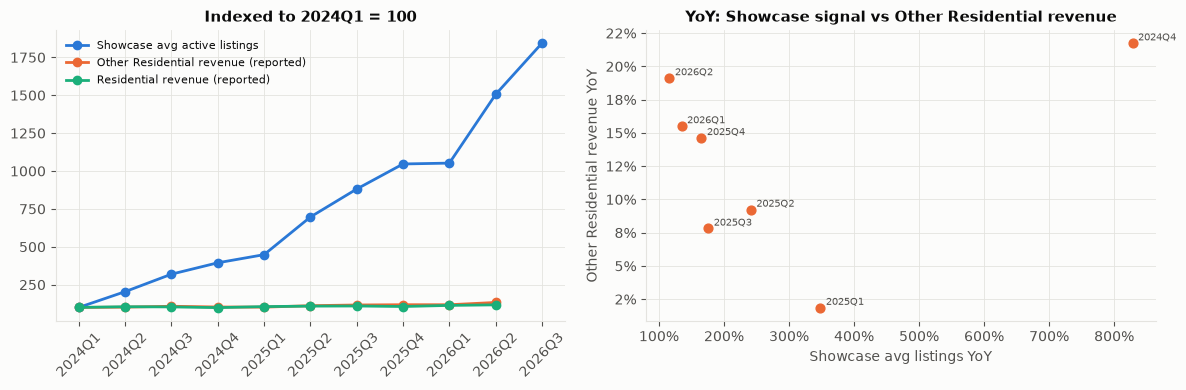

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
x = bt.loc["2024Q1":"2026Q3"]
xi = x.index.astype(str)
axes[0].plot(xi, x["sc_avg"] / x["sc_avg"].loc["2024Q1"] * 100, color=C["s1"], marker="o", label="Showcase avg active listings")
axes[0].plot(xi, x["oth_reported"] / x["oth_reported"].loc["2024Q1"] * 100, color=C["s2"], marker="o", label="Other Residential revenue (reported)")
axes[0].plot(xi, x["res_reported"] / x["res_reported"].loc["2024Q1"] * 100, color=C["s3"], marker="o", label="Residential revenue (reported)")
axes[0].set_title("Indexed to 2024Q1 = 100"); axes[0].legend(fontsize=8); axes[0].tick_params(axis="x", rotation=45)
ww = bt.loc["2024Q4":"2026Q2"]
axes[1].scatter(ww["sc_avg_yoy"], ww["oth_reported_yoy"], color=C["s2"], s=40, zorder=3)
for qt, r in ww.iterrows():
    axes[1].annotate(str(qt), (r["sc_avg_yoy"], r["oth_reported_yoy"]), fontsize=7, color=C["ink2"], xytext=(4, 2), textcoords="offset points")
axes[1].set_xlabel("Showcase avg listings YoY"); axes[1].set_ylabel("Other Residential revenue YoY")
axes[1].xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}")); axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
axes[1].set_title("YoY: Showcase signal vs Other Residential revenue")
save(fig, "benchmark")

In [11]:
q3 = bt.loc[["2025Q3", "2026Q2", "2026Q3"], ["sc_avg", "share_avg", "n_snaps", "sc_avg_yoy", "oth_consensus", "oth_consensus_yoy", "res_consensus_yoy"]]
q3.style.format({"sc_avg": "{:,.0f}", "share_avg": "{:.2%}", "sc_avg_yoy": "{:+.0%}", "oth_consensus": "{:,.0f}", "oth_consensus_yoy": "{:+.1%}", "res_consensus_yoy": "{:+.1%}"}, na_rep="")

,sc_avg,share_avg,n_snaps,sc_avg_yoy,oth_consensus,oth_consensus_yoy,res_consensus_yoy
quarter,,,,,,,
2025Q3,"29,455",1.20%,5,+176%,"85,184,114",+24.0%,+10.6%
2026Q2,"50,329",2.07%,5,+116%,"95,494,300",+13.9%,+9.1%
2026Q3,"61,621",2.49%,9,+109%,"87,859,228",+3.1%,+1.5%


## 4. Flows: is the slowdown saturation or churn?

This compares each snapshot with the next one, property by property (raw feed, deduplicated, date-filtered to June 2025 onwards).
- **Outflows from Showcase:**
  - *Sold proxy*: the property was PENDING and then dropped out of the feed.
  - *Delisted / other exit*: the property was FOR_SALE and then dropped out.
  - *Flag dropped*: the property is still listed but no longer Showcase.
- **Inflows to Showcase:**
  - *New listing*: a property absent last snapshot that appears as Showcase.
  - *Flag added*: an existing listing that turns Showcase.

All counts are converted to **per-week rates**, because the gap between snapshots ranges from 7 to 38 days. Exits over a long gap are understated, since short-lived listings can appear and disappear unseen, so compare weekly-cadence periods with care.

In [12]:
flows = q("""
with s as (
  select property_id, rundate::date d, property_status st, property_type pt, nvl(is_showcase_listing, false) sc
  from bots.z.listings_all where rundate >= '2025-06-01'
  qualify row_number() over (partition by property_id, rundate order by insert_update_time desc) = 1
), dates as (select distinct d from s), nd as (select d, lead(d) over (order by d) d2 from dates),
out_ as (
  select nd.d, nd.d2, count_if(a.sc) sc_t,
    count_if(a.sc and b.property_id is not null and not b.sc) flag_dropped,
    count_if(a.sc and b.property_id is null and a.st = 'PENDING') exit_sold,
    count_if(a.sc and b.property_id is null and a.st <> 'PENDING') exit_delisted
  from nd join s a on a.d = nd.d left join s b on b.property_id = a.property_id and b.d = nd.d2
  where nd.d2 is not null group by 1, 2),
in_ as (
  select nd.d, nd.d2,
    count_if(b.sc and a.property_id is null) in_new,
    count_if(b.sc and a.property_id is not null and not a.sc) in_flag,
    count_if(b.property_id is not null and a.property_id is null) new_all,
    count_if(b.sc and a.property_id is null) / nullif(count_if(b.property_id is not null and a.property_id is null), 0) entry_share,
    -- clean: new FOR_SALE non-lot listings only (drops the ~49k foreclosure rows that first appear on 2026-08-25)
    count_if(b.sc and a.property_id is null and b.st = 'FOR_SALE' and b.pt <> 'LOT')
      / nullif(count_if(a.property_id is null and b.st = 'FOR_SALE' and b.pt <> 'LOT'), 0) entry_share_clean
  from nd join s b on b.d = nd.d2 left join s a on a.property_id = b.property_id and a.d = nd.d
  where nd.d2 is not null group by 1, 2)
select * from out_ join in_ using (d, d2) order by d""")
flows["d"] = pd.to_datetime(flows["d"]); flows["d2"] = pd.to_datetime(flows["d2"])
flows["gap_days"] = (flows["d2"] - flows["d"]).dt.days
wk = flows.copy()
for c in ["flag_dropped", "exit_sold", "exit_delisted", "in_new", "in_flag", "new_all"]:
    wk[c] = flows[c] / flows["gap_days"] * 7
wk["inflow"] = wk["in_new"] + wk["in_flag"]
wk["outflow"] = wk["flag_dropped"] + wk["exit_sold"] + wk["exit_delisted"]
wk["net"] = wk["inflow"] - wk["outflow"]
wk["exit_rate"] = wk["outflow"] / flows["sc_t"]   # weekly % of the Showcase stock leaving
cols = ["d", "d2", "gap_days", "sc_t", "in_new", "in_flag", "exit_sold", "exit_delisted", "flag_dropped", "net", "exit_rate", "entry_share", "entry_share_clean"]
wk[cols].style.format({c: "{:,.0f}" for c in cols[3:10]} | {"exit_rate": "{:.1%}", "entry_share": "{:.2%}", "entry_share_clean": "{:.2%}", "d": "{:%Y-%m-%d}", "d2": "{:%Y-%m-%d}"})

,d,d2,gap_days,sc_t,in_new,in_flag,exit_sold,exit_delisted,flag_dropped,net,exit_rate,entry_share,entry_share_clean
0,2025-06-01,2025-07-09,38,"25,227","1,684",608,719,866,182,525,7.0%,1.21%,1.34%
1,2025-07-09,2025-08-01,23,"28,077","1,265",789,835,944,170,106,6.9%,1.18%,1.31%
2,2025-08-01,2025-08-16,15,"28,426","1,377",836,905,883,147,278,6.8%,1.18%,1.31%
3,2025-08-16,2025-09-01,16,"29,021","1,802",904,"1,008","1,029",191,478,7.7%,1.31%,1.43%
4,2025-09-01,2025-09-16,15,"30,113","1,729","1,014",959,881,190,713,6.7%,1.37%,1.53%
5,2025-09-16,2025-10-01,15,"31,640","1,957","1,064","1,158","1,159",288,416,8.2%,1.46%,1.63%
6,2025-10-01,2025-10-16,15,"32,532","2,134","1,124",932,954,271,"1,100",6.6%,1.58%,1.78%
7,2025-10-16,2025-11-01,16,"34,890","3,602","1,306","1,216","1,317",344,"2,030",8.2%,1.61%,1.78%
8,2025-11-01,2025-12-02,31,"39,531",538,856,940,"1,262",217,"-1,025",6.1%,1.39%,1.57%
9,2025-12-02,2025-12-16,14,"34,991",624,674,"1,034","1,114",170,"-1,020",6.6%,1.25%,1.45%


In [13]:
def period(a, b, lab):
    m = wk[(wk["d"] >= a) & (wk["d2"] <= b)]
    g = m["gap_days"]
    r = {c: (m[c] * g).sum() / g.sum() for c in ["in_new", "in_flag", "exit_sold", "exit_delisted", "flag_dropped", "net", "new_all"]}
    r["exit_rate"] = (m["outflow"] * g).sum() / (m["sc_t"] * g).sum()
    r["entry_share"] = (m["in_new"] * g).sum() / (m["new_all"] * g).sum()
    r["avg_stock"] = m["sc_t"].mean()
    return pd.Series(r, name=lab)
cmp = pd.concat([period("2025-08-01", "2025-10-17", "Aug–mid-Oct 2025"),
                 period("2026-03-01", "2026-06-03", "Mar–May 2026"),
                 period("2026-08-02", "2026-10-07", "Aug–early Oct 2026"),
                 period("2026-08-25", "2026-10-07", "Weekly cadence (25 Aug–6 Oct 2026)")], axis=1).T
cmp.style.format({c: "{:,.0f}" for c in ["in_new", "in_flag", "exit_sold", "exit_delisted", "flag_dropped", "net", "new_all", "avg_stock"]} | {"exit_rate": "{:.1%}", "entry_share": "{:.2%}"})

,in_new,in_flag,exit_sold,exit_delisted,flag_dropped,net,new_all,exit_rate,entry_share,avg_stock
Aug–mid-Oct 2025,"1,800",987,993,982,217,595,"130,276",7.2%,1.38%,"30,346"
Mar–May 2026,"3,435","1,607","1,696","1,356",529,"1,461","148,500",7.8%,2.31%,"45,609"
Aug–early Oct 2026,"3,155","1,506","1,990","2,112",277,282,"134,429",7.1%,2.35%,"61,605"
Weekly cadence (25 Aug–6 Oct 2026),"3,362","1,665","2,140","2,259",296,331,"138,945",7.6%,2.42%,"62,129"


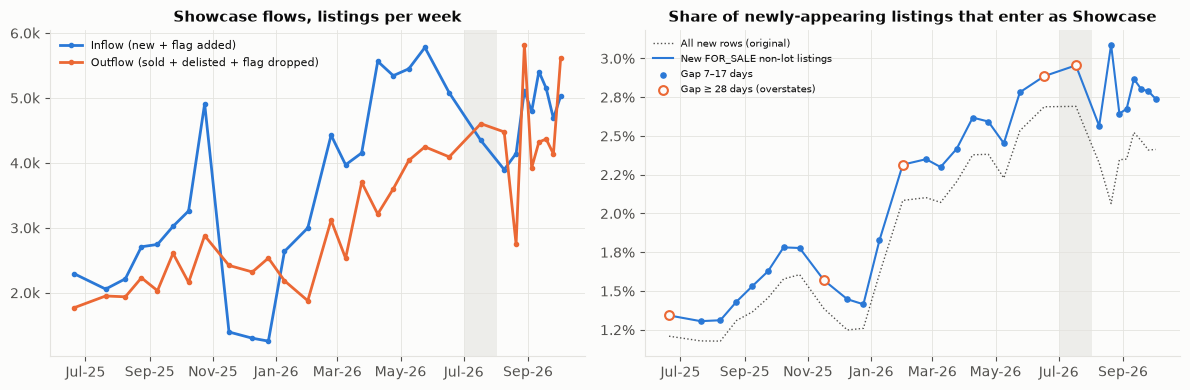

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
f = wk[wk["d"] >= "2025-06-01"]
mid = f["d"] + (f["d2"] - f["d"]) / 2
axes[0].plot(mid, f["inflow"], color=C["s1"], marker="o", markersize=3, label="Inflow (new + flag added)")
axes[0].plot(mid, f["outflow"], color=C["s2"], marker="o", markersize=3, label="Outflow (sold + delisted + flag dropped)")
axes[0].set_title("Showcase flows, listings per week"); axes[0].legend(fontsize=8)
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v/1e3:.1f}k"))
axes[1].plot(mid, f["entry_share"], color=C["ink2"], lw=1, ls=":", label="All new rows (original)")
axes[1].plot(mid, f["entry_share_clean"], color=C["s1"], lw=1.5, label="New FOR_SALE non-lot listings")
long_gap = f["gap_days"] >= 28
axes[1].scatter(mid[~long_gap], f.loc[~long_gap, "entry_share_clean"], color=C["s1"], s=14, zorder=3, label="Gap 7–17 days")
axes[1].scatter(mid[long_gap], f.loc[long_gap, "entry_share_clean"], facecolor="#fcfcfb", edgecolor=C["s2"], s=40, lw=1.5, zorder=3,
                label="Gap ≥ 28 days (overstates)")
axes[1].set_title("Share of newly-appearing listings that enter as Showcase"); axes[1].legend(fontsize=7, loc="upper left")
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.1%}"))
for ax in axes:
    ax.axvspan(*V2V3_GAP, color=C["grid"], alpha=0.6, lw=0); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b-%y"))
save(fig, "flows")

### Showcase share of new listing starts, by start month (`LISTING_DETAILS`)

This series is right-censored. A listing that turns Showcase later counts in its start month, so recent months are understated until they mature. The by-snapshot entry share above is the cleaner recent read.

In [15]:
starts = q("""select date_trunc('month', date) m, count(*) starts, count_if(is_showcase_listing) sc_starts
              from bots.z.listing_details where date >= '2024-01-01' group by 1 order by 1""")
starts["share"] = starts["sc_starts"] / starts["starts"]
starts["m"] = pd.to_datetime(starts["m"]).dt.to_period("M")
starts.set_index("m").T.style.format(lambda v: f"{v:.2%}" if isinstance(v, float) and v < 1 else f"{v:,.0f}")

m,2024-01,2024-02,2024-03,2024-04,2024-05,2024-06,2024-07,2024-08,2024-09,2024-10,2024-11,2024-12,2025-01,2025-02,2025-03,2025-04,2025-05,2025-06,2025-07,2025-08,2025-09,2025-10,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09,2026-10
starts,"471,000","452,625","554,334","325,239","463,423","564,738","518,972","546,748","524,402","490,249","435,168","363,472","324,745","530,445","491,834","668,448","682,702","253,275","739,038","586,049","540,498","534,920","484,247","257,659","338,467","464,384","548,635","593,535","633,207","350,181","596,459","852,104","621,372","121,434"
sc_starts,"2,096","2,213","3,008","2,260","3,370","4,531","4,510","4,947","4,958","5,015","4,613","3,977","3,940","7,403","7,361","10,613","11,059","4,273","13,561","11,315","11,632","12,667","11,462","5,724","8,373","13,530","17,343","19,927","21,959","11,845","20,168","25,270","18,810","2,954"
share,0.45%,0.49%,0.54%,0.69%,0.73%,0.80%,0.87%,0.90%,0.95%,1.02%,1.06%,1.09%,1.21%,1.40%,1.50%,1.59%,1.62%,1.69%,1.83%,1.93%,2.15%,2.37%,2.37%,2.22%,2.47%,2.91%,3.16%,3.36%,3.47%,3.38%,3.38%,2.97%,3.03%,2.43%


### Why the entry share looks lumpy

Most of the snapshot-to-snapshot movement comes from how we collect the data:
- **Gap length.** A listing that goes live and switches Showcase on between two snapshots is first seen *already* Showcase,
  so it counts as entering as Showcase. Long gaps (Jun→Jul 2025: 38 days; Jan→Feb 2026: 31 days; Jun→Jul→Aug 2026: 30–31 days)
  therefore read high. The move to weekly snapshots from 2026-08-25 lowers the series mechanically.
- **Foreclosure rows.** About 49k FORECLOSED / PRE_FORECLOSURE rows first appear on 2026-08-25 and count as "new", which
  drags the original series down to 2.06%. The clean series excludes them.
- **The 2025-11-01 snapshot** is an outlier, with 2.63M total listings.
- **Seasonality.** Every year the share dips over Nov–Dec.

A cleaner read is listing starts by month, measuring whether each listing carries Showcase **within 120 days of starting**
(agent-listed homes). Recent months are right-censored: September 2026 has had only 1–5 weeks to switch on.

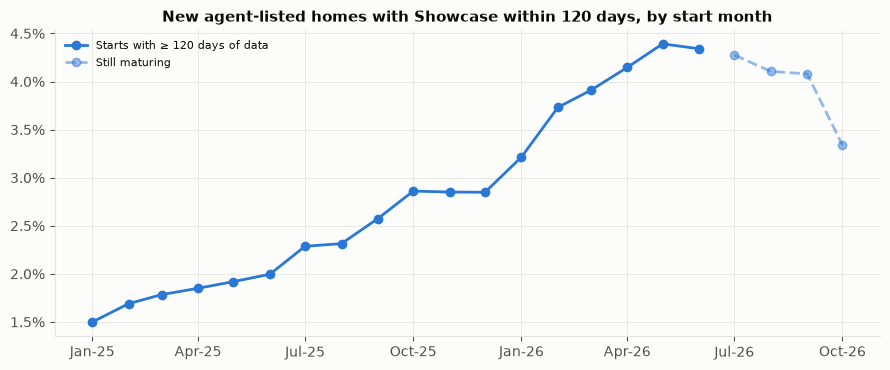

mo,25-01,25-02,25-03,25-04,25-05,25-06,25-07,25-08,25-09,25-10,25-11,25-12,26-01,26-02,26-03,26-04,26-05,26-06,26-07,26-08,26-09,26-10
starts,"170,610","275,535","263,181","361,884","369,690","141,664","371,105","317,148","298,475","294,137","260,253","136,642","180,561","232,846","300,262","327,531","351,518","191,691","311,607","420,702","344,403","66,965"
share,1.50%,1.69%,1.78%,1.85%,1.92%,2.00%,2.29%,2.31%,2.58%,2.86%,2.85%,2.85%,3.21%,3.73%,3.91%,4.15%,4.39%,4.34%,4.28%,4.11%,4.08%,3.34%


In [16]:
mat = q("""
with snaps as (select property_id, rundate::date rd, property_type pt, property_status st, broker_name bn, nvl(is_showcase_listing,false) sc
               from bots.z.listings_all where rundate >= '2024-12-01'
               qualify row_number() over (partition by property_id, rundate::date order by insert_update_time desc) = 1),
first as (select d.listing_id, d.property_id, d.date from bots.z.listing_details d
          join snaps a on a.property_id = d.property_id and a.rd = d.date
          where d.date >= '2025-01-01' and a.pt in ('SINGLE_FAMILY','CONDO','TOWNHOUSE') and a.st = 'FOR_SALE'
            and nullif(trim(a.bn),'') is not null),
sc as (select f.listing_id, max(iff(b.sc, 1, 0)) sc120
       from first f join snaps b on b.property_id = f.property_id and b.rd between f.date and dateadd('day', 120, f.date) group by 1)
select date_trunc('month', f.date) mo, count(*) starts, sum(sc120) sc120 from first f join sc using (listing_id) group by 1 order by 1""")
mat["mo"] = pd.to_datetime(mat["mo"]); mat["share"] = mat["sc120"] / mat["starts"]
fig, ax = plt.subplots(figsize=(9, 3.8))
done = mat["mo"] < "2026-07-01"
ax.plot(mat.loc[done, "mo"], mat.loc[done, "share"], color=C["s1"], marker="o", label="Starts with ≥ 120 days of data")
ax.plot(mat.loc[~done, "mo"], mat.loc[~done, "share"], color=C["s1"], marker="o", ls="--", alpha=0.5, label="Still maturing")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.1%}")); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b-%y"))
ax.set_title("New agent-listed homes with Showcase within 120 days, by start month"); ax.legend(fontsize=8, loc="upper left")
save(fig, "new_listing_share_matured")
mat.set_index(mat["mo"].dt.strftime("%y-%m"))[["starts", "share"]].T.style.format(lambda v: f"{v:.2%}" if v < 1 else f"{v:,.0f}")

## 5. Broker mix (snapshot-level Showcase listings by brokerage brand)

In [17]:
BRAND = """CASE
 WHEN NULLIF(TRIM(broker_name), '') IS NULL THEN 'N/A (no broker)'
 WHEN bn LIKE '%OPENDOOR%' THEN 'Opendoor'
 WHEN bn LIKE '%RE/MAX%' OR bn LIKE '%REMAX%' OR bn LIKE '%RE MAX%' THEN 'RE/MAX'
 WHEN bn LIKE '%HOWARD HANNA%' THEN 'Howard Hanna'
 WHEN bn LIKE '%COLDWELL BANKER%' THEN 'Coldwell Banker'
 WHEN bn LIKE '%KELLER WILLIAMS%' OR bn LIKE 'KW %' OR bn LIKE '% KW %' THEN 'Keller Williams'
 WHEN bn LIKE '%EXP REALTY%' OR bn = 'EXP' THEN 'eXp Realty'
 WHEN bn LIKE '%COMPASS%' THEN 'Compass'
 WHEN bn LIKE '%BERKSHIRE HATHAWAY%' OR bn LIKE 'BHHS%' OR bn LIKE '% BHHS%' THEN 'Berkshire Hathaway HS'
 WHEN bn LIKE '%CENTURY 21%' OR bn LIKE '%CENTURY21%' THEN 'Century 21'
 WHEN bn LIKE '%REAL BROKER%' OR bn = 'REAL' OR bn LIKE 'REAL BROKERAGE%' THEN 'Real Broker'
 WHEN bn LIKE '%LPT REALTY%' THEN 'LPT Realty'
 WHEN bn LIKE '%SOTHEBY%' THEN 'Sotheby''s'
 WHEN bn LIKE '%REDFIN%' THEN 'Redfin'
 WHEN bn LIKE '%SAMSON PROPERTIES%' THEN 'Samson Properties'
 ELSE 'Other' END"""
DATES = ["2025-10-01", "2026-04-02", "2026-07-02", "2026-08-02", "2026-09-01", "2026-10-06"]
br = q(f"""with a as (select date, listings, is_showcase_listing sc, broker_name,
             UPPER(REGEXP_REPLACE(broker_name, '^Listing by:\\\\s*', '', 1, 1, 'i')) bn
           from bots.z.listings_agg where date in ({",".join(f"'{d}'" for d in DATES)}))
           select date, {BRAND} brand, sum(listings) n, sum(iff(sc, listings, 0)) sc from a group by 1, 2""")
br["date"] = pd.to_datetime(br["date"]).dt.strftime("%Y-%m-%d")
sc_p = br.pivot_table(index="brand", columns="date", values="sc", aggfunc="sum").fillna(0)
pen = (sc_p / br.pivot_table(index="brand", columns="date", values="n", aggfunc="sum")).fillna(0)
sc_p["Δ Jul→Oct 2026"] = sc_p["2026-10-06"] - sc_p["2026-07-02"]
sc_p = sc_p.sort_values("2026-10-06", ascending=False)
display(sc_p.style.format("{:,.0f}").set_caption("Active Showcase listings by brand"))
pen.loc[sc_p.index].style.format("{:.1%}").set_caption("Showcase penetration of the brand's active listings")

date,2025-10-01,2026-04-02,2026-07-02,2026-08-02,2026-09-01,2026-10-06,Δ Jul→Oct 2026
brand,,,,,,,
Other,"13,380","17,382","24,443","23,447","23,264","24,514",71
N/A (no broker),"6,149","8,277","12,604","12,749","12,627","12,936",332
RE/MAX,"1,574","2,105","4,626","4,603","4,685","4,831",205
Keller Williams,"2,098","2,779","4,051","4,413","4,450","4,633",582
Berkshire Hathaway HS,"1,877","2,300","3,476","3,375","3,396","3,436",-40
eXp Realty,"1,697","2,179","3,119","3,100","3,075","3,160",41
Real Broker,689,"1,036","1,523","1,614","1,631","1,777",254
Coldwell Banker,912,"1,466","1,809","1,683","1,648","1,689",-120
Howard Hanna,"1,556","1,116","1,599","1,423","1,384","1,408",-191


date,2025-10-01,2026-04-02,2026-07-02,2026-08-02,2026-09-01,2026-10-06
brand,,,,,,
Other,1.1%,1.6%,1.9%,1.9%,2.0%,2.1%
N/A (no broker),1.0%,1.3%,1.8%,1.9%,1.8%,1.8%
RE/MAX,1.5%,2.2%,4.3%,4.5%,4.6%,4.8%
Keller Williams,1.5%,2.2%,2.8%,3.1%,3.2%,3.3%
Berkshire Hathaway HS,4.7%,6.5%,8.5%,8.7%,8.9%,9.0%
eXp Realty,2.8%,3.8%,4.8%,4.9%,5.0%,5.1%
Real Broker,3.4%,4.8%,5.8%,6.2%,6.4%,6.9%
Coldwell Banker,1.2%,2.0%,2.2%,2.1%,2.1%,2.2%
Howard Hanna,11.1%,9.7%,10.1%,9.5%,9.1%,9.3%


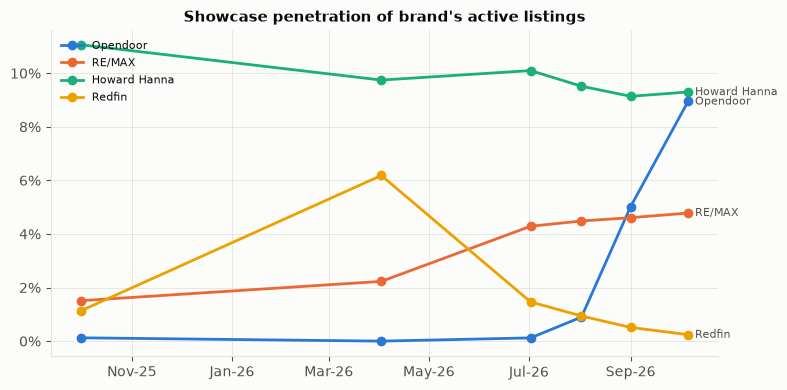

In [18]:
fig, ax = plt.subplots(figsize=(8, 4))
focus = [("Opendoor", C["s1"]), ("RE/MAX", C["s2"]), ("Howard Hanna", C["s3"]), ("Redfin", C["s4"])]
xd = pd.to_datetime(pen.columns)
for b, col in focus:
    ax.plot(xd, pen.loc[b], color=col, marker="o", label=b)
    ax.annotate(b, (xd[-1], pen.loc[b].iloc[-1]), xytext=(5, 0), textcoords="offset points", fontsize=8, color=C["ink2"], va="center")
ax.set_title("Showcase penetration of brand's active listings"); ax.legend(fontsize=8, loc="upper left")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}")); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b-%y"))
save(fig, "brokers")

### Geography: Showcase listings by state (snapshot-level)

In [19]:
geo = q("""select date, state, sum(listings) n, sum(iff(is_showcase_listing, listings, 0)) sc from bots.z.listings_agg
           where date in ('2025-10-01', '2026-07-02', '2026-10-06') group by 1, 2""")
geo["date"] = pd.to_datetime(geo["date"]).dt.strftime("%Y-%m-%d")
g = geo.pivot_table(index="state", columns="date", values="sc", aggfunc="sum").fillna(0)
gp = geo.pivot_table(index="state", columns="date", values="n", aggfunc="sum")
t = pd.DataFrame({"sc_oct25": g["2025-10-01"], "sc_jul26": g["2026-07-02"], "sc_oct26": g["2026-10-06"],
                  "Δ Jul→Oct": g["2026-10-06"] - g["2026-07-02"],
                  "pen_jul26": g["2026-07-02"] / gp["2026-07-02"], "pen_oct26": g["2026-10-06"] / gp["2026-10-06"],
                  "share_of_sc_oct26": g["2026-10-06"] / g["2026-10-06"].sum()}).sort_values("sc_oct26", ascending=False)
t.head(15).style.format({"sc_oct25": "{:,.0f}", "sc_jul26": "{:,.0f}", "sc_oct26": "{:,.0f}", "Δ Jul→Oct": "{:+,.0f}",
                         "pen_jul26": "{:.1%}", "pen_oct26": "{:.1%}", "share_of_sc_oct26": "{:.1%}"})

,sc_oct25,sc_jul26,sc_oct26,Δ Jul→Oct,pen_jul26,pen_oct26,share_of_sc_oct26
state,,,,,,,
FL,"6,314","10,073","9,888",-185,3.3%,3.3%,15.6%
TX,"2,377","4,682","4,951",+269,1.4%,1.6%,7.8%
CA,"2,258","4,463","4,706",+243,2.7%,2.8%,7.4%
NC,"1,789","3,463","3,731",+268,3.2%,3.5%,5.9%
GA,"1,549","3,109","2,945",-164,3.1%,3.1%,4.7%
CO,"1,181","2,479","2,637",+158,4.0%,4.4%,4.2%
AZ,"1,308","1,999","2,526",+527,2.9%,3.6%,4.0%
SC,"1,048","2,295","2,406",+111,3.6%,4.0%,3.8%
WA,680,"1,968","2,205",+237,3.4%,3.9%,3.5%


### Showcase share of each state's listings

Each state's active Showcase listings as a share of its own FOR_SALE + PENDING listings, **excluding vacant lots** (about 18% of
inventory and almost never Showcase) and foreclosure rows. Snapshots: 2026-10-06 vs 2025-10-01.

The denominator doesn't require a broker name. Broker-name coverage varies by state (VT is mostly blank), which makes an
"agent-listed only" share unreliable at state level.

US (ex-lots): 3.23% vs 1.68% a year ago


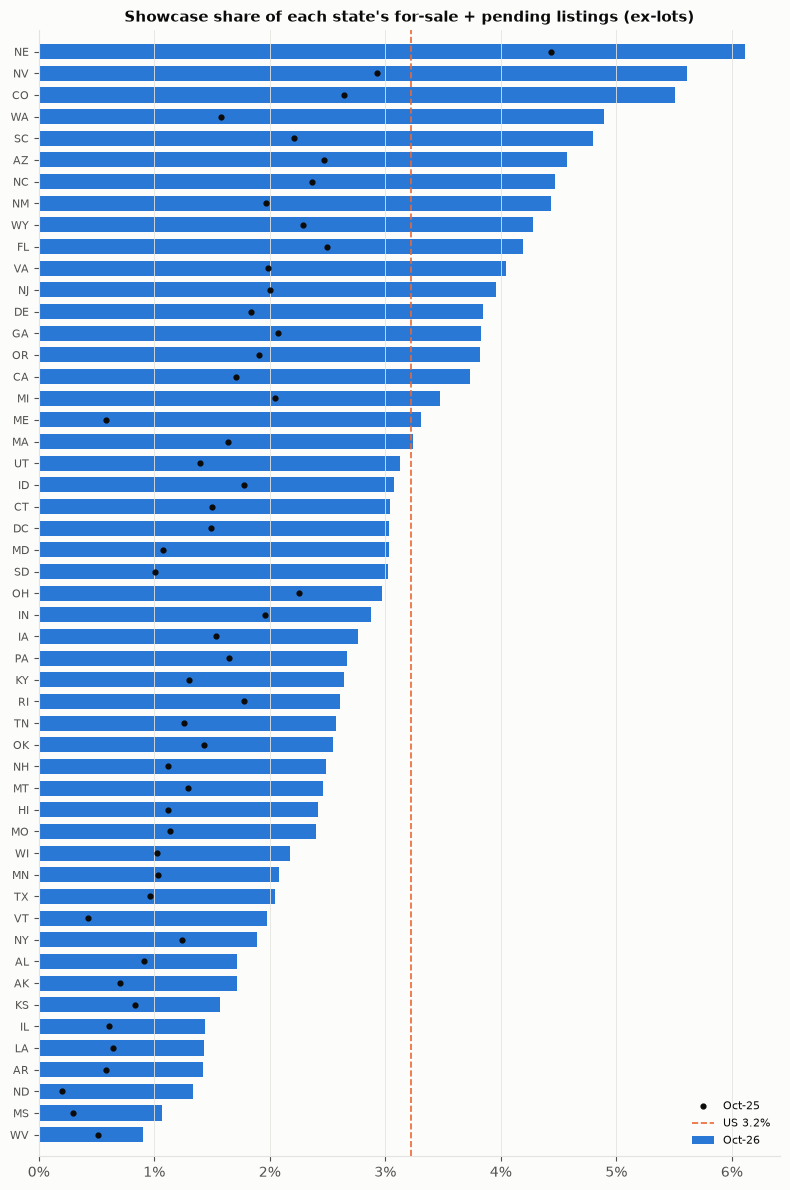

,listings,showcase,share Oct-26,share Oct-25,Δ pp
state,,,,,
NE,"9,965",609,6.11%,4.44%,+1.68
NV,"21,166","1,188",5.61%,2.93%,+2.68
CO,"47,815","2,633",5.51%,2.64%,+2.86
WA,"45,075","2,204",4.89%,1.58%,+3.31
SC,"50,160","2,405",4.79%,2.21%,+2.58
AZ,"55,216","2,525",4.57%,2.47%,+2.10
NC,"83,450","3,729",4.47%,2.37%,+2.10
NM,"11,751",521,4.43%,1.96%,+2.47
WY,"3,649",156,4.28%,2.29%,+1.99


In [20]:
US = set("AL AK AZ AR CA CO CT DE DC FL GA HI ID IL IN IA KS KY LA ME MD MA MI MN MS MO MT NE NV NH NJ NM NY NC ND OH OK OR PA RI SC SD TN TX UT VT VA WA WV WI WY".split())
gs = q("""
with s as (select rundate::date d, state, property_type pt, property_status st, nvl(is_showcase_listing,false) sc
  from bots.z.listings_all where rundate::date in ('2025-10-01','2026-10-06')
  qualify row_number() over (partition by property_id, rundate::date order by insert_update_time desc) = 1)
select state, d, count_if(st in ('FOR_SALE','PENDING') and pt <> 'LOT') n,
       count_if(sc and st in ('FOR_SALE','PENDING') and pt <> 'LOT') sc
from s group by 1, 2""")
gs = gs[gs["state"].isin(US)]
gs["d"] = pd.to_datetime(gs["d"]).dt.strftime("%Y-%m-%d")
n_ = gs.pivot_table(index="state", columns="d", values="n", aggfunc="sum")
s_ = gs.pivot_table(index="state", columns="d", values="sc", aggfunc="sum")
sh = pd.DataFrame({"listings": n_["2026-10-06"], "showcase": s_["2026-10-06"],
                   "share Oct-26": s_["2026-10-06"] / n_["2026-10-06"], "share Oct-25": s_["2025-10-01"] / n_["2025-10-01"]})
sh["Δ pp"] = (sh["share Oct-26"] - sh["share Oct-25"]) * 100
nat = pd.Series({"listings": n_["2026-10-06"].sum(), "showcase": s_["2026-10-06"].sum(),
                 "share Oct-26": s_["2026-10-06"].sum() / n_["2026-10-06"].sum(), "share Oct-25": s_["2025-10-01"].sum() / n_["2025-10-01"].sum()})
sh = sh.sort_values("share Oct-26", ascending=False)
print(f"US (ex-lots): {nat['share Oct-26']:.2%} vs {nat['share Oct-25']:.2%} a year ago")

fig, ax = plt.subplots(figsize=(8, 12))
y = np.arange(len(sh))[::-1]
ax.barh(y, sh["share Oct-26"], color=C["s1"], height=0.7, label="Oct-26")
ax.scatter(sh["share Oct-25"], y, color=C["ink"], s=12, zorder=3, label="Oct-25")
ax.axvline(nat["share Oct-26"], color=C["s2"], lw=1.2, ls="--", label=f"US {nat['share Oct-26']:.1%}")
ax.set_yticks(y, sh.index, fontsize=8); ax.set_ylim(-1, len(sh))
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}")); ax.grid(axis="y", visible=False)
ax.set_title("Showcase share of each state's for-sale + pending listings (ex-lots)"); ax.legend(fontsize=8, loc="lower right")
save(fig, "state_share")
sh.style.format({"listings": "{:,.0f}", "showcase": "{:,.0f}", "share Oct-26": "{:.2%}", "share Oct-25": "{:.2%}", "Δ pp": "{:+.2f}"})

## 6. Zillow Preview (lower bound)

This data comes only from v3 (2026-08-02 onwards), and a listing showing a different badge is missed.

In [21]:
pv = q("""select count(*) listings, count_if(is_showcase_listing) also_showcase,
            avg(datediff('day', preview_start_date, preview_end_date)) avg_obs_preview_days,
            count_if(listing_end > preview_end_date) seen_after_preview, count_if(listing_status = 'current') still_current
          from bots.z.listing_details where use_zillow_preview""")
pv_snap = snap.set_index("date").join(q("""select date, sum(iff(is_zillow_preview, listings, 0)) preview from bots.z.listings_agg
                                        where date >= '2026-08-01' group by 1""").assign(date=lambda d: pd.to_datetime(d["date"])).set_index("date"), how="inner")["preview"]
display(pv)
pv_snap.to_frame().T

,listings,also_showcase,avg_obs_preview_days,seen_after_preview,still_current
0,1050,229,9.795238,683,797


date,2026-08-02,2026-08-16,2026-08-25,2026-09-01,2026-09-08,2026-09-15,2026-09-22,2026-09-29,2026-10-06
preview,294,245,264,287,288,238,235,234,214


## Findings

**Headline: Showcase is still roughly doubling year on year, but the active base has plateaued since July at about 61â€“64k listings.** The reason is that new Showcase additions have stopped growing while exits keep pace with the larger base. Exit behaviour itself has not changed.

1. **Level (6 Oct 2026):**
   - 63.2k active Showcase listings, **2.59% of for-sale + pending** listings, against 1.35% a year ago. The count is +94% YoY.
   - In the two months since the 2 Aug snapshot the base grew only about +2.6k (60.6k â†’ 63.2k), after about +4k a month in Marchâ€“June.
   - YoY growth is fading steadily: +128% in early June, +113% in early August, +94% now.
   - The share keeps creeping up (2.45% â†’ 2.59%) because total inventory is seasonally flat to down.
2. **Flows: the base has reached a steady state.** At weekly cadence (25 Augâ€“6 Oct):
   - Inflows are **~5.0k/week** (3.4k new listings entering as Showcase + 1.7k existing listings switched on). That is the same as Marchâ€“May 2026 (5.0k/week).
   - Weekly exits are **~7.6% of the base**, against 7.8% in spring and 7.2% a year ago.
   - With a base of about 62k, exits (~4.7k/week) now nearly match inflows, so net adds are ~+0.3k/week, against ~+1.5k/week in spring.
   - At these rates the implied steady state is about 66k.
   - Showcase being *removed* from live listings is negligible (~0.3k/week, about 0.5% of the base).
   - **So this is not churn. It is a flat gross-add rate in a seasonally slowing listing market.**
   - New listings enter as Showcase at a **flat ~2.4% rate** since spring (1.4% a year ago).
   - Much of the snapshot-to-snapshot lumpiness comes from how we collect the data (section 4 note).
2b. **Reconciliation to management (section 2b).** On a comparable basis, our data tracks management's series closely.
   - Comparable basis: new agent-listed homes that carry Showcase at any point.
   - Q2-26 is **4.4% vs management's ~5%**. Management reads 1.03â€“1.20x ours in every quarter since Q4-24, with no drift.
   - The 2.59% figure is a different measure: share of the active stock, including vacant lots.
   - **Monthly and quarterly view, and the Q3-26 estimate (section 2c).** Management's wording ("as of the end of Q3", "end of March", year-end chart points) implies a national, new for-sale, quarter-end measure. Two versions, each applying one Showcase cutoff consistently across quarters:
     - **A. Point-in-time** (Showcase by quarter-end): quarterly average 3.65% â†’ **3.97%** (+8.7% Q/Q). Sequential estimate **5.4%** (80% band 4.9â€“5.9%; backtest MAPE 5.9%).
     - **B. Reporting-lag** (Showcase by quarter-end + 35 days; Q3 projected using older cohorts' growth of 1.04â€“1.08x): 4.15% â†’ **4.29%** (+3.5%). Sequential estimate **5.2%** (80% band 4.5â€“5.8%; MAPE 6.7%). **B is the base case.**
     - Both point to **flat to slightly up** Q/Q. An earlier "slightly down" read compared fully matured Q2 months with immature Q3 months, which is inconsistent.
     - The backtest bias is about +3%, driven by Q1-25 and Q1-26 overshoots (our Q4â†’Q1 jump is sharper than management's). Q3 has no such pattern.
3. **Brokers:**
   - **Opendoor** is the clear new adopter: 3 â†’ **314** Showcase listings since July, about 9% of its inventory.
   - **RE/MAX** (4.8% penetration), **Keller Williams** (+0.6k), **Real Broker** (+0.25k) and Samson are still growing.
   - **Howard Hanna** keeps sliding: 11.1% penetration a year ago, 9.3% now, âˆ’190 listings since July.
   - **Redfin's** spring test (335 in April) has nearly gone (13).
   - Coldwell Banker and BHHS are flat.
   - By state, FL (âˆ’185), GA, NJ, PA, NY and OH fell from July to October. AZ (+527), TX, NC, CA and WA grew.
   - **Share of each state's listings** (ex-lots), against 3.2% for the US:
     - **Highest:** NE 6.1%, NV 5.6%, CO 5.5%, WA 4.9%, SC 4.8%.
     - **Lowest:** WV 0.9%, MS 1.1%, ND/AR/LA/IL ~1.4%.
     - **Lagging large states:** TX 2.0%, NY 1.9%.
     - Every state rose YoY. WA (+3.3pp) and CO (+2.9pp) rose most; OH (+0.7pp) and NY (+0.65pp) least.
4. **Benchmark (weak, short history):**
   - Showcase YoY has correlation 0.30 with Other Residential revenue YoY and 0.57 with Residential YoY. That is n = 7 quarters, all with Showcase growth above +100%.
   - The level correlation (0.97) is just a shared trend.
   - A "last year Ã— (1 + Î²Â·signal YoY)" nowcast gave 4.7% MAPE against 5.1% for consensus. It called beat/miss only 40% of the time (n = 5).
   - Revenue-per-listing scaling fails (+81% bias), because Showcase is a small part of Other Residential.
   - **Treat the signal as a directional read on adoption, not a revenue predictor.**
   - The Q3 signal (+109% YoY average listings) implies Other Residential around $101M against $88M consensus. But Q3 Residential is guided flat because of the shift into Mortgages, so this comparison is not reliable.
5. **Preview:** about 210â€“290 listings per snapshot, falling, and about 1.05k distinct listings since August. 22% also carry Showcase, and the median observed Preview window is one snapshot. This is consistent with management's "quite small".

**Caveats:**
- There is no July 2026 snapshot (v2â†’v3), and cadence changed from twice monthly to weekly. Flows are per-week rates, but exits over long gaps are understated.
- The 1 Nov 2025 snapshot is an outlier: total inventory jumped to 2.63M.
- On a comparable definition, we run about 10â€“15% below management: 4.4% vs ~5% in Q2-26. The likely causes are listings that start and go pending between snapshots, Zillow's exact "new listings" definition, and Showcase flags we miss.
  - Scale our number up by about 1.14x to approximate management's metric.
  - Treat the 2.59% active-stock share as a separate measure, not as an estimate of management's number.
- Brand mapping uses `broker_name` string matching, and about 20% of Showcase listings have no broker.